In [1]:
# import numpy as np
import pandas as pd
import matplotlib.gridspec as gridspec

import matplotlib.pyplot as plt
from matplotlib.backends.backend_agg import FigureCanvas
from scipy.spatial import distance
import random as rand
import pickle
from scipy import stats
import time


# allow us to re-use the framework from the src directory
import sys, os
sys.path.append(os.path.abspath(os.path.join('../')))

import max_ent.examples.grid_9_by_9 as G
from max_ent.utility.support import *
from max_ent.gridworld import Directions


rand.seed(123)
np.random.seed(123)

In [22]:
def plot_subtype(x, y, df, hue, title, filename, min_label=0, max_label=None, list_threshold3= None, dropna = False):
    
    #print(f"{[min_label, max_label]}")
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    sns.set_theme(style="whitegrid")
    sns.set(font_scale=2)
    sns.color_palette("viridis", as_cmap=True)
    
    fig = plt.figure(figsize=(30, 15))
    # grid for pairs of subplots
    rows = len(list_threshold3)
    cols = 5
    grid = plt.GridSpec(rows, cols)

    #figure, axis = plt.subplots(len(list_threshold3), 2, figsize=(25, 30))
    #plt.tight_layout()
    #print(axis)

    #for index, t3, sub_plot in enumerate(list_threshold3,axis):
    for i in range(rows):
        
        t3 = list_threshold3[i]
        # create fake subplot just to title set of subplots
        fake = fig.add_subplot(grid[i, :])
        # '\n' is important
        #fake.set_title(f'{title+str(t3)}\n', fontweight='semibold')
        fake.set_axis_off()
        
        # create subgrid for two subplots without space between them
        # <https://matplotlib.org/2.0.2/users/gridspec.html>
        gs = gridspec.GridSpecFromSubplotSpec(1, cols, subplot_spec=grid[i, :])

        # real subplot #1
        ax = fig.add_subplot(gs[0])
        ax.set_title(f'Det. = 0.0')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) & ((df['type']=='SOFAI w/ S1 ra=0.0 REF') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel("Perc. of Use of S1 and S2")
        colors = ['orange', 'blue']
        sns.set_palette(sns.color_palette(colors))
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S1','s2'], ci=None,hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S1', 'S2'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,0].set_title('Myopic')'''

        # real subplot #2
        ax = fig.add_subplot(gs[1], sharey=ax)
        ax.set_title(f'Det. = 0.25')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=0.25 REF') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S1','s2'], ci=None,hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S1', 'S2'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,1].set_title('No Myopic')
        
        # real subplot #2
        ax = fig.add_subplot(gs[2], sharey=ax)
        ax.set_title(f'Det. = 0.5')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=0.5 REF') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S1','s2'], ci=None,hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S1', 'S2'])
        if max_label: g.set_ylim([min_label, max_label])
            
        # real subplot #2
        ax = fig.add_subplot(gs[3], sharey=ax)
        ax.set_title(f'Det. = 0.75')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=0.75 REF') ) ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S1','s2'], ci=None, hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S1', 'S2'])
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], ci=None,hue=hue,markers=True, dashes=False, style=hue)
        if max_label: g.set_ylim([min_label, max_label])
            
        # real subplot #2
        ax = fig.add_subplot(gs[4], sharey=ax)
        ax.set_title(f'Det. = 1.0')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=1.0 REF') ) ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], ci=None, hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S1', 'S2'])
        #df_means = temp_df.groupby(x)[y].agg("mean").reset_index()
        #g = sns.scatterplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue)
        #g = sns.scatterplot(ax=ax, x=x, y=y, data=df_means)
        if max_label: g.set_ylim([min_label, max_label])
        

    plt.savefig(filename+'.pdf', bbox_inches='tight')
    plt.show()

In [2]:

'''label='length'
list_df = [df3[label],df4[label]]
list_mean=[(np.mean(x)+np.std(x))*1.1 for x in list_df]

print(np.max(list_mean))
'''
'''def min_max(label, df, df2, df3, df4, df7):
    list_df = [df[label],df2[label],df3[label],df4[label],df7[label]]
    list_mean=[(np.mean(x) + np.sign(np.mean(x)) * np.std(x))*1.1 for x in list_df]
    print(list_mean)
    min_label=np.min(list_mean)
    max_label=np.max(list_mean)
    
    if min_label < 0 and max_label < 0:
        max_label = 0
    elif min_label > 0 and max_label > 0:
        min_label = 0
    
    return min_label, max_label'''

def min_max(label, df):
    list_df = df[label]
    list_mean=[(np.mean(x) + np.sign(np.mean(x)) * np.std(x))*1.1 for x in list_df]
    #print(list_mean)
    min_label=np.min(list_mean)
    max_label=np.max(list_mean)
    
    if min_label < 0 and max_label < 0:
        max_label = 0
    elif min_label > 0 and max_label > 0:
        min_label = 0
    
    return min_label, max_label

In [3]:
def f(count_stat):
    Z = []

    for x in range(9):
        temp_grid = []
        for y in range(9):
            #print(f"({x},{y})")
            temp_grid.append(np.sum(count_stat[0][y][8-x]))
            
        #print(temp_grid)
        Z.append(temp_grid)
    return np.array(Z)

In [4]:
def runSOFAI(n, c, mca_01_myopic, threshold1, threshold2, threshold3, threshold4, threshold5, ra, n_trajectories, trial, mca_s2, title, constraints, n_grid=None, onlyS1=False):
    s1_ra0 = System1Solver(myopic=False, ra=ra)
    
    if mca_01_myopic is None: 
        if onlyS1: 
            mca_01_myopic = MCA(n=n, c=c, s1=s1_ra0, demo=None, threshold1=threshold1, threshold2=threshold2, threshold3 = threshold3, threshold4 = threshold4, threshold5=1, only_s1= True)
        else: 
            mca_01_myopic = MCA(n=n, c=c, s1=s1_ra0, s2=mca_s2.s2, demo=None, threshold1=threshold1, threshold2=threshold2, threshold3 = threshold3, threshold4 = threshold4, threshold5=1)
    else:
        mca_01_myopic.setGrid(grid=n, constraints=c)  
        
    demo_mca_01_myopic = mca_01_myopic.generate_trajectories(n_trajectories, discard_not_feasable=False)
    #temp_matrix_mca_01_myopic = count_states(demo_mca_01_myopic.trajectories, c_cfg.mdp, n, constraints, bootstrap = bootstrap)
    temp_dict=build_dict(type_mca=title, agent=mca_01_myopic, t1=threshold1, t2=threshold2, t3= threshold3, demo = demo_mca_01_myopic, constraints= constraints, trial = trial, n_grid = n_grid, n_trajectories=n_trajectories)
    #f1 = G.plot_world(f'SOFAI_myopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
    #df = pd.concat([df, temp_dict])

    temp_jsdiv = {}
    temp_jsdiv['t3'] = threshold3
    temp_jsdiv['t4'] = threshold4
    temp_jsdiv['jsdiv'] = js_divergence((mca_s2.modelSelf.ntra_per_transition + 1E-10)/np.sum(mca_s2.modelSelf.ntra_per_transition + 1E-10), (mca_01_myopic.modelSelf.ntra_per_transition + 1E-10)/np.sum(mca_01_myopic.modelSelf.ntra_per_transition + 1E-10))
    temp_jsdiv['type'] = title
    temp_jsdiv = pd.DataFrame(data=temp_jsdiv, index=[0])
    
    return mca_01_myopic, temp_dict, temp_jsdiv, demo_mca_01_myopic

In [5]:
n_grids = 10

n_trials = 500 #

n_trajectories = 1
goal = 40

bootstrap = 0
n_constraints = 18
n_actions = 4

threshold1 = 0 # 
threshold2 = 1 # 
list_threshold2 = [0.5, 0.95, 1, 1.5] #0.95 # THIS REMOVE SECOND CONDITION
threshold3 = 1.0
#list_threshold3 = [0.1, 0.3, 0.6, 0.9] # try with 0.9 or 1.0 / myopic and non-myopic S1
list_threshold3 = [1,] # try with 0.9 or 1.0 / myopic and non-myopic S1
#list_threshold3 = [0,1] # try with 0.9 or 1.0 / myopic and non-myopic S1
threshold4 = 0 # 

p_slip = 0.1

In [6]:

df = pd.DataFrame()
df2 = pd.DataFrame()
df3 = pd.DataFrame()
df4 = pd.DataFrame()
df7 = pd.DataFrame()

In [7]:

time_tot = int(round(time.time() * 1000))
n_models = 15

df = pd.DataFrame()
js_div = pd.DataFrame()
mca = []
size = 9

mca_1 = None
mca_2 = None
mca_3 = None
mca_4 = None
mca_5 = None

list_initial_state = [0,1,2,3,4,5,6,7,8,9,18,27,36,45,54,63,72,73,74,75,76,77,78,79,80,17,26,35,44,53,62,71]

for n_grid in range(n_grids):

    resetModelSelf = True
    mca_agents = [None for i in range(100)]
    mca_s10 = None
    mca_s1025 = None
    mca_s105 = None
    mca_s1075 = None
    mca_s11 = None

    blue, green, cs, ca, start, goal = generate_constraints(9, n_constraints=n_constraints,goal = goal, action=n_actions)
    constraints = {'blue': blue, 'green': green, 'cs':cs, 'ca':ca}

    

    #list_available = [x for x in range(size ** 2)]
    list_available = np.array(list_initial_state)
    list_available = np.setdiff1d(list_available, blue)
    list_available = np.setdiff1d(list_available, green)
    list_available = np.setdiff1d(list_available, cs)
    list_available = np.setdiff1d(list_available, [goal])

    demo_list =[]
    
    #generate nomminal 
    time_exp = int(round(time.time() * 1000))
    n, n_cfg, demo_n, f1 = create_world('Nominal', blue, green, start=start, goal=goal, n_trajectories=200, p_slip=p_slip, draw=False)
    time_exp = int(round(time.time() * 1000)) - time_exp 
    temp_matrix = count_states(demo_n.trajectories, n_cfg.mdp, n, constraints)
    '''temp_dict=build_dict(temp_matrix, type_mca='nominal')
    temp_dict['time'] = time_exp / n_trajectories
    df = pd.concat([df, temp_dict])'''

    '''Z_distr = f(temp_matrix)
    Z_distr = np.array(Z_distr)
    Z_distr = Z_distr + 1E-3
    Z_distr[8-int(start/9)][int(start%9)]=0
    Z_distr[8-int(goal/9)][int(goal%9)] = 0

    #plt.imshow(Z_distr/np.sum(Z_distr), cmap='hot', interpolation='nearest')
    #plt.show()

    #Z_distr/np.sum(Z_distr)
    distr = np.array(Z_distr/np.sum(Z_distr))

    new_distr = []
    for idistr in range(len(distr)):
        new_distr.append(distr[len(distr)-idistr-1])

    new_distr = np.array(new_distr)'''


    ##cs = np.random.choice(np.arange(0,81), replace=False, p = new_distr.flatten(), size = n_constraints)
    #constraints = {'blue': blue, 'green': green, 'cs':cs, 'ca':ca}
    print(f"Start: {start} Goal: {goal} \nConstraints: {constraints}")
    #exit()

    #generate constrained grid
    cc = [1, 2]
    time_exp = int(round(time.time() * 1000))
    c, c_cfg, demo_c, f2 = create_world('Constrained', blue, green, cs, ca, cc, start=start, goal=goal, check=True, n_trajectories=200, p_slip=p_slip, draw=False)
    time_exp = int(round(time.time() * 1000)) - time_exp 

    #COMPUTE STATISTICS FOR NOMINAL
    temp_matrix = count_states(demo_n.trajectories, c_cfg.mdp, n, constraints)
    temp_dict=build_dict(temp_matrix, type_mca='nominal', demo = demo_n, constraints= constraints, trial = 0, n_grid = n_grid)
    temp_dict['time'] = time_exp / n_trajectories
    ###df = pd.concat([df, temp_dict])

    #COMPUTE STATISTICS FOR CONSTRAINED
    temp_matrix = count_states(demo_c.trajectories, c_cfg.mdp, n, constraints)
    temp_dict=build_dict(temp_matrix, type_mca='const', demo = demo_c, constraints= constraints, trial = 0, n_grid = n_grid)
    temp_dict['time'] = time_exp / n_trajectories
    ###df = pd.concat([df, temp_dict])

    for trial in range(n_trials):
        #print(f"Iteration {trial}")
        #generate constraints

        #start = np.random.choice(list_available)
        #start = np.random.choice(list_initial_state)
        '''generate = True
        while generate:
            # generate start state from the list of non-constrained states
            start = np.random.choice(list_available)
            start_x = start % size
            start_y = start // size

            goal_x = goal % size
            goal_y = goal // size

            if abs(start_x-goal_x) > 3 or abs(start_y-goal_y) > 3:
                generate = False'''

        '''blue = [21,  9, 59,  1,  0, 20]
        green = [42, 18, 76, 41, 23, 30]
        cs = [63, 74, 13, 39, 48, 38]
        ca = [Directions.DOWN_LEFT, Directions.UP_LEFT]'''
        ##start =7
        ##goal = 65


        if resetModelSelf: 
            mca_s2 = MCA(n=n, c=c, demo=None, threshold5=1, only_s2=True)
        else:
            mca_s2.setGrid(grid=n, constraints=c)

        demo_mca_s2 = mca_s2.generate_trajectories(n_trajectories)
        #temp_matrix_mca_s2 = count_states(demo_mca_s2.trajectories, c_cfg.mdp, n, constraints, bootstrap = bootstrap)
        temp_dict=build_dict( type_mca='S2', agent=mca_s2 , demo = demo_mca_s2, constraints= constraints, trial = trial, n_grid = n_grid, n_trajectories=n_trajectories)
        #f1 = G.plot_world(f'Only S2', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s2, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
        df = pd.concat([df, temp_dict])

        ####################################            ONLY S1      ###################
       

        mca_s10, temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_s10, threshold1=0, threshold2=1, threshold3=1, threshold4=0, threshold5 = 1, ra = 0, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'S1 ra=0.0', constraints= constraints, onlyS1 = True)
        df = pd.concat([df, temp_dict])
        js_div = pd.concat([js_div, temp_jsdiv])

        mca_s1025, temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_s1025, threshold1=0, threshold2=1, threshold3=1, threshold4=0, threshold5 = 1, ra = 0.25, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'S1 ra=0.25', constraints= constraints, onlyS1 = True)
        df = pd.concat([df, temp_dict])
        js_div = pd.concat([js_div, temp_jsdiv])

        mca_s105, temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_s105, threshold1=0, threshold2=1, threshold3=1, threshold4=0, threshold5 = 1, ra = 0.5, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'S1 ra=0.5', constraints= constraints, onlyS1 = True)
        df = pd.concat([df, temp_dict])
        js_div = pd.concat([js_div, temp_jsdiv])

        mca_s1075, temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_s1075, threshold1=0, threshold2=1, threshold3=1, threshold4=0, threshold5 = 1, ra = 0.75, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'S1 ra=0.75', constraints= constraints, onlyS1 = True)
        df = pd.concat([df, temp_dict])
        js_div = pd.concat([js_div, temp_jsdiv])

        mca_s11, temp_dict, temp_jsdiv, demo = runSOFAI(n, c, mca_s11, threshold1=0, threshold2=1, threshold3=1, threshold4=0, threshold5 = 1, ra = 1, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'S1 ra=1.0', constraints= constraints, onlyS1 = True)
        df = pd.concat([df, temp_dict])
        js_div = pd.concat([js_div, temp_jsdiv])

        for i_threshold2 in range(len(list_threshold2)):
            threshold2 = list_threshold2[i_threshold2]
            
            for i_threshold3 in range(len(list_threshold3)):

                print(f"\n ************** Threshold (t2: {list_threshold2[i_threshold2]}, t3:{list_threshold3[i_threshold3]}): Trial {trial} grid {n_grid} ******************")
                threshold3 = list_threshold3[i_threshold3]

                mca_agents[i_threshold2 * n_models + 0], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold2 * n_models + 0], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.0', constraints= constraints)
                df = pd.concat([df, temp_dict])
                js_div = pd.concat([js_div, temp_jsdiv])

                mca_agents[i_threshold2 * n_models + 1], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold2 * n_models + 1], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.25, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.25', constraints= constraints)
                df = pd.concat([df, temp_dict])
                js_div = pd.concat([js_div, temp_jsdiv])

                mca_agents[i_threshold2 * n_models + 2], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold2 * n_models + 2], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.5, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.5', constraints= constraints)
                df = pd.concat([df, temp_dict])
                js_div = pd.concat([js_div, temp_jsdiv])

                mca_agents[i_threshold2 * n_models + 3], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold2 * n_models + 3], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.75, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.75', constraints= constraints)
                df = pd.concat([df, temp_dict])
                js_div = pd.concat([js_div, temp_jsdiv])

                mca_agents[i_threshold2 * n_models + 4], temp_dict, temp_jsdiv, demo = runSOFAI(n, c, mca_agents[i_threshold2 * n_models + 4], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 1, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=1.0', constraints= constraints)
                df = pd.concat([df, temp_dict])
                js_div = pd.concat([js_div, temp_jsdiv])

                ####################################            MCA FOR REFLECTION      ###################

                mca_agents[i_threshold2 * n_models + 5], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold2 * n_models + 5], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.0 REF', constraints= constraints)
                df = pd.concat([df, temp_dict])
                js_div = pd.concat([js_div, temp_jsdiv])

                mca_agents[i_threshold2 * n_models + 6], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold2 * n_models + 6], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.25, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.25 REF', constraints= constraints)
                df = pd.concat([df, temp_dict])
                js_div = pd.concat([js_div, temp_jsdiv])

                mca_agents[i_threshold2 * n_models + 7], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold2 * n_models + 7], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.5, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.5 REF', constraints= constraints)
                df = pd.concat([df, temp_dict])
                js_div = pd.concat([js_div, temp_jsdiv])

                mca_agents[i_threshold2 * n_models + 8], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold2 * n_models + 8], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.75, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.75 REF', constraints= constraints)
                df = pd.concat([df, temp_dict])
                js_div = pd.concat([js_div, temp_jsdiv])

                mca_agents[i_threshold2 * n_models + 9], temp_dict, temp_jsdiv, demo = runSOFAI(n, c, mca_agents[i_threshold2 * n_models + 9], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 1, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=1.0 REF', constraints= constraints)
                if i_threshold2 == len(list_threshold2)-1: demo_list = demo_list + demo.trajectories
                df = pd.concat([df, temp_dict])
                js_div = pd.concat([js_div, temp_jsdiv])

                if ((trial+1) % 50 ==0 and (trial+1) < n_trials): 
                    r=mca_agents[i_threshold2 * n_models + 5].reflect(p=0.2, verbose=False)
                    r=mca_agents[i_threshold2 * n_models + 6].reflect(p=0.2, verbose=False)
                    r=mca_agents[i_threshold2 * n_models + 7].reflect(p=0.2, verbose=False)
                    r=mca_agents[i_threshold2 * n_models + 8].reflect(p=0.2, verbose=False)
                    r=mca_agents[i_threshold2 * n_models + 9].reflect(p=0.2, verbose=False)
                    print(f"Temperature: {mca_agents[i_threshold2 * n_models + 5].temperature}")

                resetModelSelf = False

        time_exp = int(round(time.time() * 1000))
        start = np.random.choice(np.setdiff1d(list_initial_state, cs))
        n.start[0] = start
        print(f"start {start}")


'''f1 = G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s1_nb_noMyopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
#f1 = G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s1_nb_Myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'Only S2', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s2, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'SOFAI_myopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'SOFAI_noMyopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_noMyopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
'''
time_tot = int(round(time.time() * 1000)) - time_tot
print(f"Total time: {time_tot}")


[0.9625 0.0625 0.0625 0.9625 0.9625 0.0625 0.9625 0.9625]
Start: 7 Goal: 40 
Constraints: {'blue': [], 'green': [], 'cs': array([65, 59, 60,  4, 70, 54, 31, 78,  8, 44,  9, 37, 76, 29, 73, 80, 63,
       79]), 'ca': [DOWN_LEFT, UP_RIGHT, LEFT, UP_LEFT]}
[0.9625 0.0625 0.0625 0.9625 0.9625 0.0625 0.9625 0.9625]

 ************** Threshold (t2: 0.5, t3:1): Trial 0 grid 0 ******************

 ************** Threshold (t2: 0.95, t3:1): Trial 0 grid 0 ******************

 ************** Threshold (t2: 1, t3:1): Trial 0 grid 0 ******************

 ************** Threshold (t2: 1.5, t3:1): Trial 0 grid 0 ******************
start 62

 ************** Threshold (t2: 0.5, t3:1): Trial 1 grid 0 ******************

 ************** Threshold (t2: 0.95, t3:1): Trial 1 grid 0 ******************

 ************** Threshold (t2: 1, t3:1): Trial 1 grid 0 ******************

 ************** Threshold (t2: 1.5, t3:1): Trial 1 grid 0 ******************
start 0

 ************** Threshold (t2: 0.5, t3:1): Trial

In [9]:
temp_demo = Demonstration(demo_list, demo.policy)
df.to_csv("dati_myopic_nomyopic"+"_risk_"+str(threshold3)+".csv")
js_div.to_csv("jsdiv_myopic_nomyopic"+"_risk_"+str(threshold3)+".csv")

{'vmin': -50, 'vmax': 10, 'cmap': <matplotlib.colors.LinearSegmentedColormap object at 0x1385a5050>}


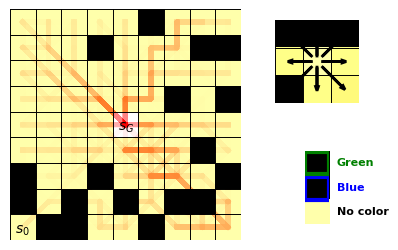

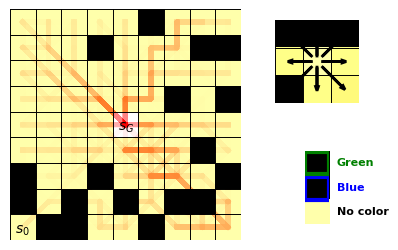

In [10]:
G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, temp_demo, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)

#G.plot_world(f'Only S2', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_c, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)

In [8]:
#temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==0.9) &  ((df['type']=='SOFAI w/ S1') )  ]
df.to_csv("all_data_allmodels_vart2_4con.csv")

In [11]:
print(ca)

[DOWN_LEFT, DOWN_RIGHT, UP_RIGHT, DOWN]


In [14]:
#x='traj_n'
#y='perc_usage'

#g=sns.lineplot(x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue="sub_type",markers=True, dashes=False)

In [18]:
df_filtered = df[(df['t2']==0.95) & ((df['type']=='SOFAI w/ S1 ra=0.0 REF') | (df['type']=='SOFAI w/ S1 ra=0.25 REF') | (df['type']=='SOFAI w/ S1 ra=0.5 REF') | (df['type']=='SOFAI w/ S1 ra=0.75 REF') | (df['type']=='SOFAI w/ S1 ra=1.0 REF'))]
df_filtered

,traj_n,length,reward,time,sub_type,time_agent,avg_time,reward_agent,avg_reward,usage,...,Length,Reward,Viol,S1_Usage,t1,t2,t3,t4,t6,t7
0,0,201,-851.656854,2059,s1,0,NaN,0.000000,NaN,0,...,201.0,-851.656854,0.5,0,0,0.95,1,0,1,0.5
0,0,201,-851.656854,2059,s2,2059,10.243781,-851.656854,-4.237099,201,...,201.0,-851.656854,0.5,0,0,0.95,1,0,1,0.5
0,0,23,-132.000000,227,s1,0,NaN,0.000000,NaN,0,...,23.0,-132.000000,0.5,0,0,0.95,1,0,1,0.5
0,0,23,-132.000000,227,s2,227,9.869565,-132.000000,-5.739130,23,...,23.0,-132.000000,0.5,0,0,0.95,1,0,1,0.5
0,0,182,-814.000000,1801,s1,0,NaN,0.000000,NaN,0,...,182.0,-814.000000,1.0,0,0,0.95,1,0,1,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499,499,13,-229.313708,41,s2,40,10.000000,-7.656854,-1.914214,4,...,13.0,-229.313708,2.0,0,0,0.95,1,0,1,0.5
499,499,5,-56.000000,10,s1,0,0.000000,-52.000000,-13.000000,4,...,5.0,-56.000000,0.5,0,0,0.95,1,0,1,0.5
499,499,5,-56.000000,10,s2,10,10.000000,-4.000000,-4.000000,1,...,5.0,-56.000000,0.5,0,0,0.95,1,0,1,0.5
499,499,4,-6.000000,10,s1,0,0.000000,-2.000000,-0.666667,3,...,4.0,-6.000000,0.0,0,0,0.95,1,0,1,0.5


/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_80732/2457037855.py:42: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S1','s2'], ci=None,hue=hue,markers=True, dashes=False)
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_80732/2457037855.py:54: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S1','s2'], ci=None,hue=hue,markers=True, dashes=False)
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_80732/2457037855.py:66: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S1','s2'], ci=None,hue=hue,markers=True, dashes=False)
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_80732/2457037855.py:77: FutureWarning: 

The `ci` parameter is depre

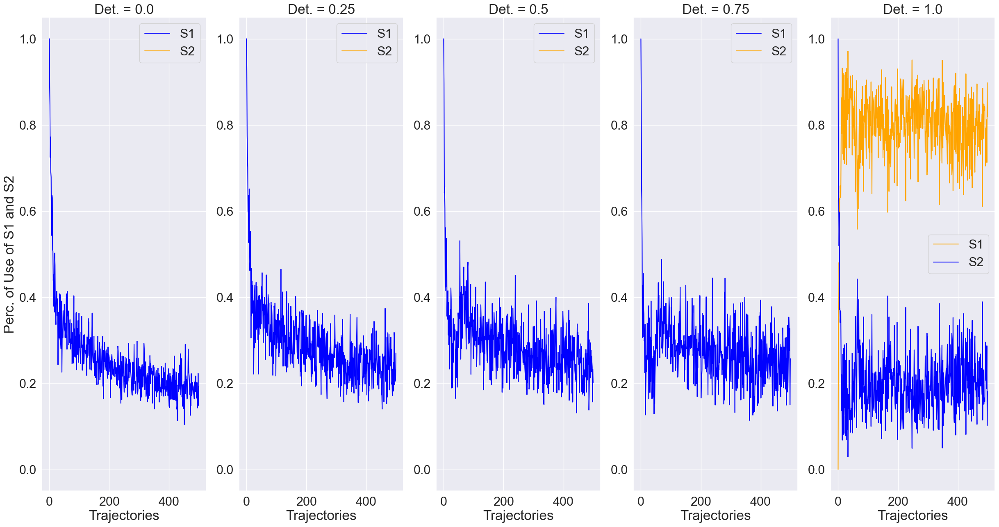

In [23]:
#df_filtered = df[(df['t2']==0.95) & ((df['type']=='SOFAI w/ S1 ra=0.0 REF') | (df['type']=='SOFAI w/ S1 ra=0.25 REF') | (df['type']=='SOFAI w/ S1 ra=0.5 REF') | (df['type']=='SOFAI w/ S1 ra=0.75 REF') | (df['type']=='SOFAI w/ S1 ra=1.0 REF'))]
x='traj_n'
y='perc_usage'
#y='avg_reward'
#y='avg_time'
filename = y+'_risk'
title="Avg frac. of times per sub-system, risk avers="

plot_subtype(x,y,df_filtered,"sub_type",title,filename, list_threshold3=[1])

In [21]:
df

,traj_n,length,reward,time,sub_type,time_agent,avg_time,reward_agent,avg_reward,usage,...,Length,Reward,Viol,S1_Usage,t1,t2,t3,t4,t6,t7
0,0,7,-19.656854,68,s1,0,NaN,0.000000,NaN,0,...,7.0,-19.656854,0.0,0,200,0.8,0.0,0,1,0.5
0,0,7,-19.656854,68,s2,68,9.714286,-19.656854,-2.808122,7,...,7.0,-19.656854,0.0,0,200,0.8,0.0,0,1,0.5
0,0,8,-73.656854,81,s1,0,NaN,0.000000,NaN,0,...,8.0,-73.656854,0.5,0,200,0.8,0.0,0,1,0.5
0,0,8,-73.656854,81,s2,81,10.125000,-73.656854,-9.207107,8,...,8.0,-73.656854,0.5,0,200,0.8,0.0,0,1,0.5
0,0,11,-87.313708,156,s1,0,NaN,0.000000,NaN,0,...,11.0,-87.313708,0.5,0,200,0.8,0.0,0,1,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499,499,40,-1062.225397,189,s2,189,9.947368,-273.941125,-14.417954,19,...,40.0,-1062.225397,9.5,0,200,0.8,1.0,0,1,0.5
499,499,14,-428.627417,40,s1,0,0.000000,-410.970563,-41.097056,10,...,14.0,-428.627417,4.0,0,200,0.8,1.0,0,1,0.5
499,499,14,-428.627417,40,s2,40,10.000000,-17.656854,-4.414214,4,...,14.0,-428.627417,4.0,0,200,0.8,1.0,0,1,0.5
499,499,86,-1008.617316,95,s1,26,0.329114,-698.960461,-8.847601,79,...,86.0,-1008.617316,6.5,0,200,0.8,1.0,0,1,0.5


/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:42: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S1','s2'], ci=None,hue=hue,markers=True, dashes=False)
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:54: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S1','s2'], ci=None,hue=hue,markers=True, dashes=False)
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:66: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S1','s2'], ci=None,hue=hue,markers=True, dashes=False)
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:77: FutureWarning: 

The `ci` parameter is depre

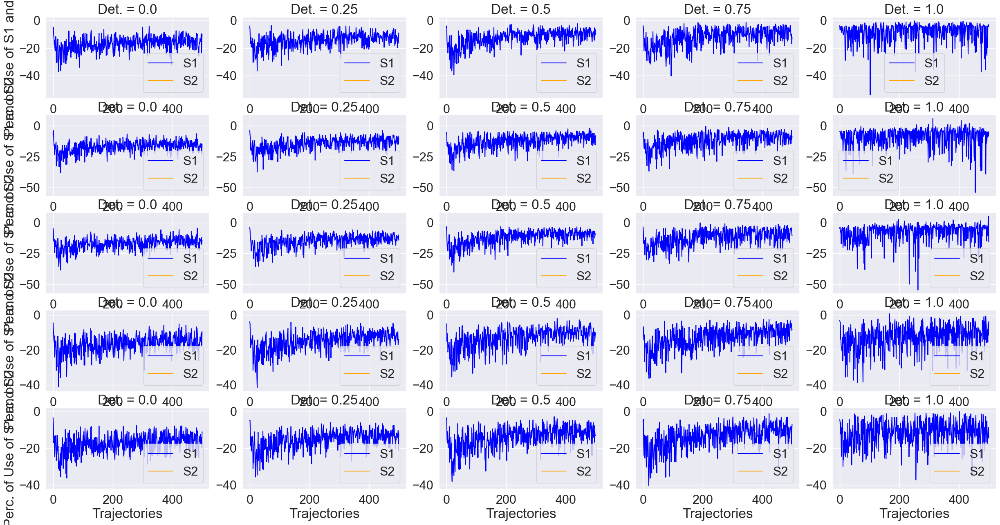

In [20]:
x='traj_n'
y='avg_reward'
#y='avg_time'
filename = y+'_risk_'
title="Avg reward per sub-system, risk avers="

plot_subtype(x,y,df, "sub_type",title,filename, list_threshold3=list_threshold3, dropna = True)


In [ ]:
x='traj_n'
y='avg_time'
filename = y+'_time'
title="Avg time per sub-system, risk avers="

plot_subtype(x,y,df, "sub_type",title,filename, list_threshold3=list_threshold3, dropna = True, max_label=40)

/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:139: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.0'], hue=hue,markers=True, dashes=False, ci=None, )
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:149: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.25'], hue=hue,markers=True, dashes=False,ci=None)
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:157: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.5'], hue=hue,markers=True, ci=None, dashes=False)
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/328

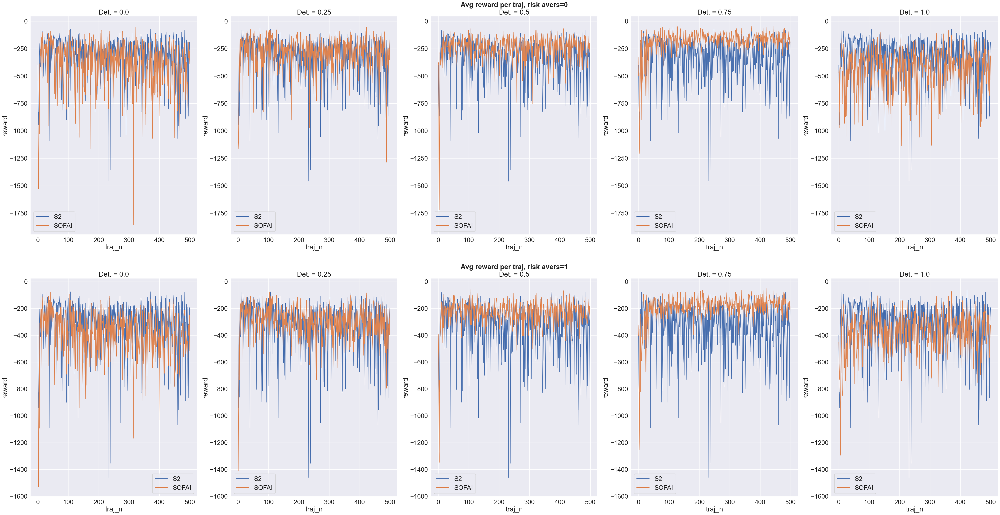

In [22]:
x='traj_n'
#y='perc_usage'
y='reward'
#y='time'


filename = 'avg_reward_per_traj'
title="Avg reward per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=[0,1])

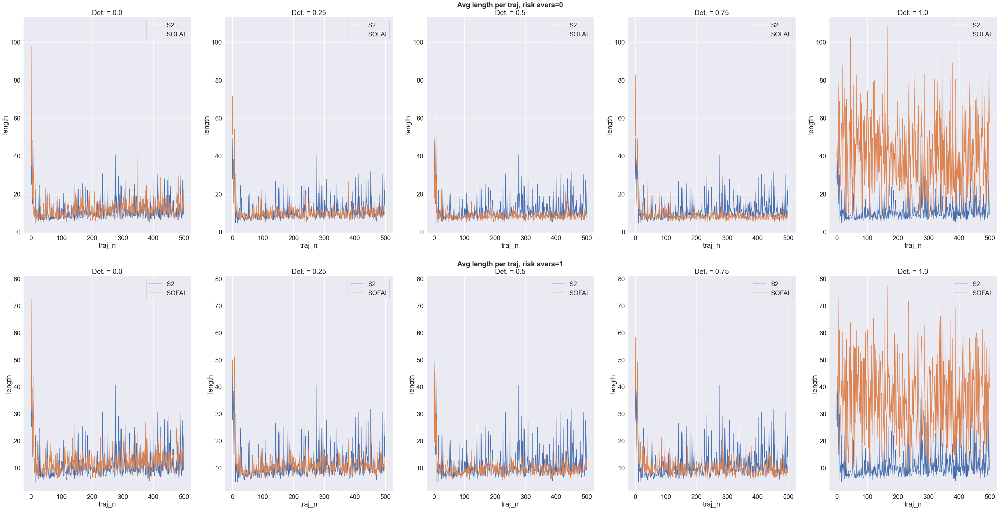

In [24]:
x='traj_n'
y='length'

filename = 'avg_length_per_traj'
title="Avg length per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3)

/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:139: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.0'], hue=hue,markers=True, dashes=False, ci=None, )
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:149: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.25'], hue=hue,markers=True, dashes=False,ci=None)
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:157: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.5'], hue=hue,markers=True, ci=None, dashes=False)
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/328

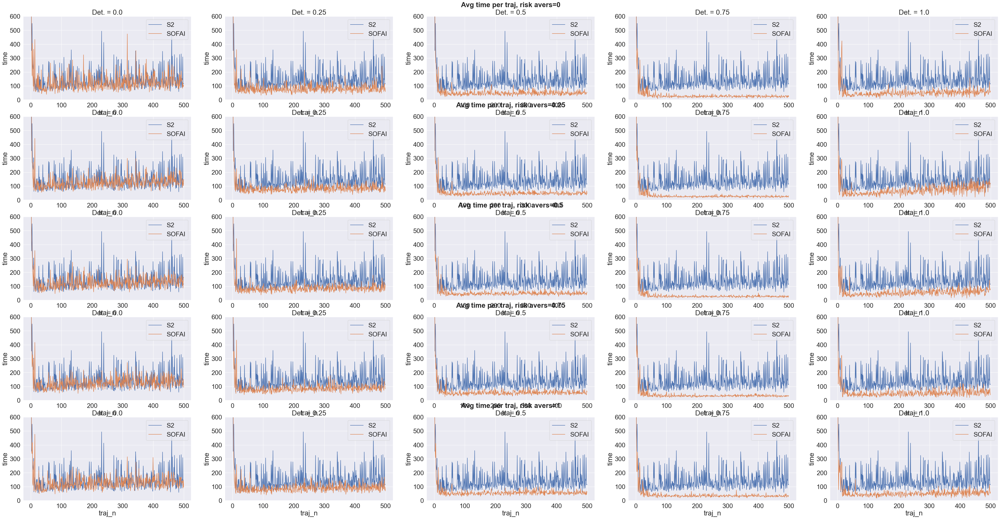

In [23]:
x='traj_n'
y='time'
filename = 'avg_time_withS1_per_traj'
title="Avg time per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3, max_label=600)

/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:139: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.0'], hue=hue,markers=True, dashes=False, ci=None, )
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:149: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.25'], hue=hue,markers=True, dashes=False,ci=None)
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/3285161075.py:157: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.5'], hue=hue,markers=True, ci=None, dashes=False)
/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/328

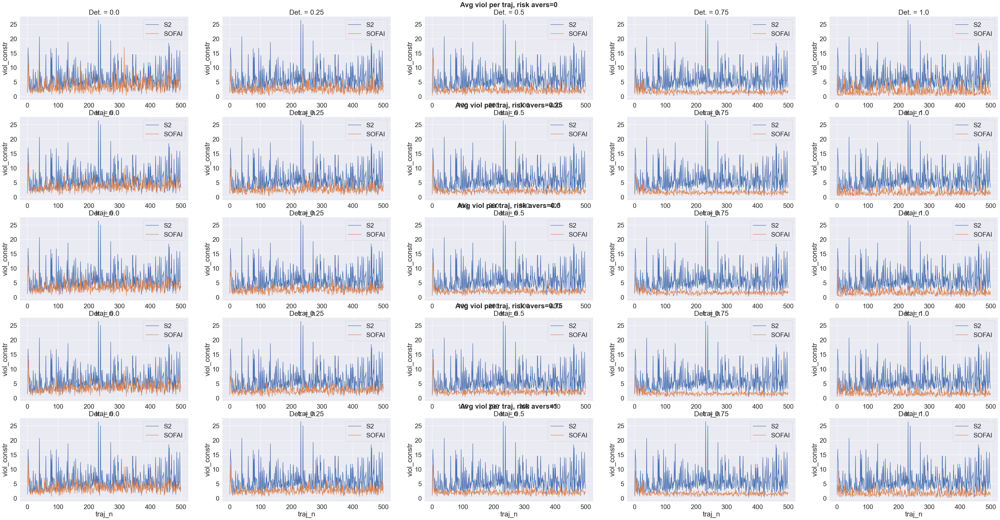

In [24]:
x='traj_n'
y='viol_constr'
filename = 'avg_viol_aggregated_per_traj'
title="Avg viol per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3, dropna=True)

In [20]:
len(demo_list)

500

In [ ]:
mca_agents[4].modelSelf.grid.world.state_index_to_point(26)

In [ ]:
temp_dictionary = demo_list[-3].__dict__

In [ ]:
mca_agents[4].trajectory_stat[2]

In [ ]:
mca_agents[4].modelSelf.trajectories[:]

In [ ]:
r[4]

In [ ]:
blue, green, cs, ca, start, goal = generate_constraints(9, n_constraints=n_constraints,goal = goal, action=n_actions)


In [ ]:
n, n_cfg, demo_n, f1 = create_world('Nominal', blue, green, start=start, goal=goal, n_trajectories=200, p_slip=p_slip, draw=True)

In [ ]:
print(mca_agents[4].modelSelf.getReward(26,1))
print(mca_agents[4].modelSelf.getRewardS2(26, maxLike=False, verbose=True))

In [ ]:
mca_agents[4].modelSelf.trajectories[0].transitions()[-1][2]

In [ ]:
mca_agents[4].modelSelf.ntra_per_transition[8,2,1]

In [38]:
action = 1
print(sum(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].values())))
print((list(mca_agents[4].modelSelf.prob_s2[8, 2,action].keys())))

for action in range(6):
    print(sum(np.array(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].keys()))*np.array(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].values())))/sum(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].values())))
print(mca_agents[4].modelSelf.ntra_per_stateAction_s2[(8, 2)])
print(mca_agents[4].modelSelf.ntra_per_stateAction[(8, 2)])

AttributeError: 'NoneType' object has no attribute 'values'

In [ ]:
#np.where(np.array(list(mca_agents[4].modelSelf.prob_s2[8,1,1,].values()))==11)
sum(list(mca_agents[4].modelSelf.prob_s2[8,2,1].keys()))/sum(list(mca_agents[4].modelSelf.prob_s2[8,2,1].values()))

In [ ]:
r = mca_agents[4].reflect(0.1)
print(sum(r[3]))
print(f"Temp: {mca_agents[4].temperature}")

In [ ]:
values_new = []
values = []
values_s2 = []
delta = []
epsilon = 1E-9
initial = 135
final = 150
for i in range(initial, initial+len(r[2])):
    '''if r[3][i]:
        values_new.append((sum(r[1][i])))#/(len(r[1][i])*168)))
    else:
        values_new.append((sum(mca.action_reward[i])))#/sum(mca.time_stat[i])))'''
    values.append(-sum(mca_agents[4].action_reward[i])*sum(mca_agents[4].time_stat[i]))
    values_new.append(-sum(r[1][i-initial])*sum(r[2][i-initial]))
    values_s2.append(-sum(mca_s2.action_reward[i])*sum(mca_s2.time_stat[i]))
    #print(f"{values[-1],values_new[-1]}")
    delta.append(math.log(values[-1]+epsilon,2) - math.log(values_new[-1]+epsilon,2))

In [ ]:
print(f"Temp: {mca_agents[4].temperature}")
threshold_delta = -0.0
compare_traj = np.array(mca_agents[4].modelSelf.trajectories[initial:final])[np.where(np.array(delta)< threshold_delta)[0]]
compare_traj = np.concatenate((np.array(r[0])[np.where(np.array(delta)>= threshold_delta)[0]], compare_traj), axis=0)
#print(Trajectory(compare_traj[0]))

epsilon = 1E-4
origTraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in mca_agents[4].modelSelf.trajectories[initial: final]:
    #total += len(trajectory.transitions())
    for transition in trajectory.transitions():
        #print(f"prima:{origTraj[transition]}")
        origTraj[transition] += 1
        #print(f"dopo:{origTraj[transition]}\n")
        
origTraj = origTraj / sum(np.reshape(origTraj, (-1,)))

newtraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in compare_traj:
    for transition in trajectory.transitions():
        newtraj[tuple(transition)] += 1	
newtraj = newtraj / sum(np.reshape(newtraj, (-1,)))



distance.jensenshannon(np.reshape(newtraj, (-1,)),np.reshape(origTraj, (-1,)))


In [ ]:
print(f"improvements {r[3]}")
values_new = []
values = []
delta = []
epsilon = 1E-9
initial = 135
final = 150
for i in range(initial, initial+len(r[2])):
    '''if r[3][i]:
        values_new.append((sum(r[1][i])))#/(len(r[1][i])*168)))
    else:
        values_new.append((sum(mca.action_reward[i])))#/sum(mca.time_stat[i])))'''
    values.append(-sum(mca_agents[4].action_reward[i])*sum(mca_agents[4].time_stat[i]))
    values_new.append(-sum(r[1][i-initial])*sum(r[2][i-initial]))
    #print(f"{values[-1],values_new[-1]}")
    delta.append(math.log(values[-1]+epsilon,2) - math.log(values_new[-1]+epsilon,2))

compare_traj = np.array(mca_agents[4].modelSelf.trajectories[initial:final])[np.where(np.array(delta)< threshold_delta)[0]]
compare_traj = np.concatenate((np.array(r[0])[np.where(np.array(delta)>= threshold_delta)[0]], compare_traj), axis=0)


size = mca_agents[4].modelSelf.grid.world.size
epsilon = 1E-4
origTraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in mca_agents[4].modelSelf.trajectories[initial: final]:
    #total += len(trajectory.transitions())
    for transition in trajectory.transitions():
        origTraj[transition] += 1	
origTraj = origTraj / sum(np.reshape(origTraj, (-1,)))

newtraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in compare_traj:
    for transition in trajectory.transitions():
        newtraj[tuple(transition)] += 1	
newtraj = newtraj / sum(np.reshape(newtraj, (-1,)))

distance.jensenshannon(np.reshape(newtraj, (-1,)),np.reshape(origTraj, (-1,)))


In [ ]:
#New is over old, i.e. it is worst, because of the higher time taken to compute the new trajectory
plt.figure(figsize=(20,10))
plt.plot(values_s2, label="S2")
plt.plot(values, label="Old")
plt.legend()

In [ ]:
for index, transition in enumerate(l.transitions()):
    print(index)

In [ ]:
np.array(mca_agents[4].modelSelf.trajectories[initial:final])[np.where(np.array(delta)< threshold_delta)[0]]

In [ ]:
compare_traj

In [ ]:
np.array(mca_agents[4].modelSelf.trajectories[0:50])[np.where(np.array(delta)< threshold_delta)[0]]

In [ ]:
np.array(r[0])[np.where(np.array(delta)>= threshold_delta)[0]]

In [ ]:
i = 4
mca_agents[4].modelSelf.trajectories[i]

In [ ]:
mca_agents[3].modelSelf.trajectories[i]

In [ ]:
mca_agents[4].trajectory_stat[i]

In [ ]:
mca_agents[3].trajectory_stat[i]

In [ ]:
sum(map(sum,mca_agents[3].action_reward))

In [ ]:
sum(map(sum,mca_agents[4].action_reward))

In [ ]:
mca_agents[4].s1.count_random

In [ ]:
sum(np.reshape(newtraj, (-1,)))

In [ ]:
r[3]

In [ ]:
mca_s2.modelSelf.getM()

In [ ]:
mca_agents[4].modelSelf.getAvgPartialReward(63)

In [6]:
!pwd
df = pd.read_csv("all_data_1.csv")
for index, value in df[:300].iterrows():
    print(str(value['traj_n'])+" "+str(value['perc_usage']))

/Users/aloreggia/Documents/GitHub/wmca/notebooks
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
1 0.0
1 1.0
1 0.0
1 1.0
1 0.3
1 0.7
1 0.2222222222222222
1 0.7777777777777778
1 0.5714285714285714
1 0.4285714285714285
1 0.6666666666666666
1 0.3333333333333333
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
3 0.0
3 1.0
3 0.0
3 1.0
3 0.1428571428571428
3 0.8571428571428571
3 0.5057471264367817
3 0.4942528735632184
3 0.6888888888888889
3 0.3111111111111111
3 1.0
3 0.0
4 0.0
4 1.0
4 0.0
4 1.0
4 0.4
4 0.6
4 0.3333333333333333
4 0.6666666666666666
4 0.75
4 0.25
4 0.8
4 0.2
5 0.0
5 1.0
5 0.0
5 1.0
5 0.2857142857142857
5 0.7142857142857143
5 0.2857142857142857
5 0.7142857142857143
5 0.5
5 0.5
5 0.8888888888888888
5 0.1111111111111111
6 0.0
6 1.0
6 0.1
6 0.9
6 0.4545454545454545
6 0.5454545454545454
6 0.2941176470588235
6 0.7058823529411765
6 0.4
6 0.6
6 0.1379310344827586
6 0.8620689655172413
7 0.0
7 1.0
7 0.5
7 0.5
7 0.6666666666666666
7 0.333333

In [35]:
df['sub_type'] = df['sub_type'].replace(['s1'], 'S1')
df['sub_type'] = df['sub_type'].replace(['S2'], 's2')
#df['type'] = df['type'].replace(['SOFAI w/ S1 ra=1.0'], 'SOFAI')

In [36]:
df['sub_type']

0      S1
0      s2
0      S1
0      s2
0      S1
       ..
499    s2
499    S1
499    s2
499    S1
499    s2
Name: sub_type, Length: 260000, dtype: object

In [31]:
fig=plt.figure(figsize=(12, 7))
sns.set(rc={'figure.figsize':(11.7,8.27)})
sns.set_theme(style="whitegrid")
sns.set(font_scale=2)
sns.color_palette("viridis", as_cmap=True)
fig.set_title(f'Det. = 1.0')
temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=1.0')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
if dropna : temp_df = temp_df.dropna()
#g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=1.0'], hue=hue,markers=True, ci=None, dashes=False)
plt.legend(labels=['S2', 'SOFAI'])
df_means = temp_df.groupby(['type','traj_n'])['time'].mean().plot()
#g = sns.scatterplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue)
g = sns.scatterplot(ax=ax, y=y, data=df_means, size=10, hue=hue)
if max_label: g.set_ylim([min_label, max_label])
#axis[0,1].set_title('No Myopic')

AttributeError: 'Figure' object has no attribute 'set_title'

<Figure size 1200x700 with 0 Axes>

In [32]:
fig=plt.figure(figsize=(12, 7))
sns.set(rc={'figure.figsize':(11.7,8.27)})
sns.set_theme(style="whitegrid")
sns.set(font_scale=2)
sns.color_palette("viridis", as_cmap=True)

label = 'viol_constr'
#label = 'time'
#label = 'reward'
#label = 'length'

temp_df = df.loc[(df['type']=='S2')  | (df['type']=='SOFAI w/ S1 ra=1.0')] #| (df['type']=='s1_nb') 
temp_df['type'] = df['type'].replace(['SOFAI w/ S1 ra=1.0'], 'SOFAI')
df_means = temp_df.groupby(by=['type','traj_n']).agg(label=(label,'mean'))
plt.legend(labels=['S2', 'SOFAI'])

 
colors = ['#747FE3', '#32cd32', '#E37346']
sns.set_palette(sns.color_palette(colors))

plt.xlabel("Trajectories")
plt.ylabel("Number of Violated Constraints")
g = sns.scatterplot(x='traj_n', y='label', data=df_means, hue='type')
#g.set_ylim([0, 1000])
g.legend_.set_title(None)
plt.savefig(f'{label}.png')

ValueError: cannot reindex on an axis with duplicate labels

<Figure size 1200x700 with 0 Axes>

In [116]:
temp_df.groupby(by=['type','traj_n']).agg(label=(label,'mean'))

label
type               traj_n        
S2                 0        896.4
                   1        593.1
                   2       1534.8
                   3        376.3
                   4        763.4
...                           ...
SOFAI w/ S1 ra=1.0 495       69.0
                   496       73.2
                   497       49.2
                   498       76.3
                   499       49.1

[1000 rows x 1 columns]

In [117]:
temp_df[label]

0      167
0      139
1      125
1       40
1       40
      ... 
497      0
498    377
498     64
499    210
499     22
Name: time, Length: 10977, dtype: int64

/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_40695/277238507.py:13: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(x=x, y=y, data=temp_df, hue_order=['S1','S2'], ci=None, hue='sub_type', markers=True, dashes=False)


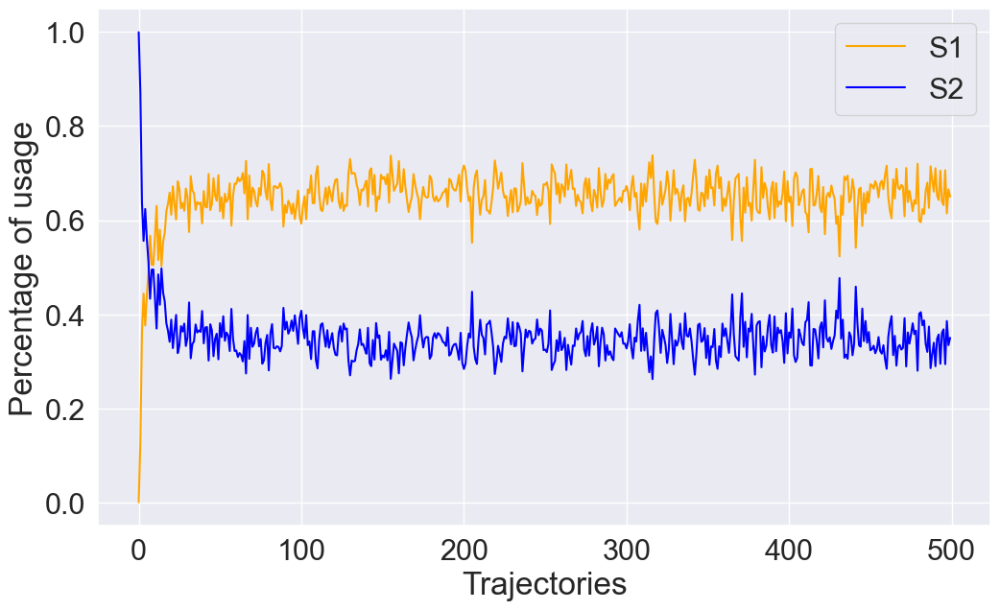

In [33]:
fig=plt.figure(figsize=(12, 7))
x='traj_n'
y='perc_usage'
temp_df = df.loc[(df['type']=='SOFAI w/ S1 ra=0.75')]

colors = ['orange', 'blue', '#E37346']
sns.set_palette(sns.color_palette(colors))

plt.legend(labels=['S1', 'S2'])
plt.xlabel("Trajectories")
plt.ylabel("Percentage of usage")

g=sns.lineplot(x=x, y=y, data=temp_df, hue_order=['S1','S2'], ci=None, hue='sub_type', markers=True, dashes=False)
g.legend_.set_title(None)
plt.savefig(f'{y}.png', bbox_inches='tight')

In [134]:
plot_subtype(x,y,df,"sub_type",title,filename, list_threshold3=list_threshold3)

0                      S2
0                      S2
0      SOFAI w/ S1 ra=1.0
0      SOFAI w/ S1 ra=1.0
1                      S2
              ...        
498    SOFAI w/ S1 ra=1.0
499                    S2
499                    S2
499    SOFAI w/ S1 ra=1.0
499    SOFAI w/ S1 ra=1.0
Name: type, Length: 20000, dtype: object

In [40]:
#S1 fully det
mca_agents[4].modelSelf.trajectories[4]

Trajectory([(1, 4, 9), (9, 2, 18), (18, 1, 19), (19, 4, 27), (27, 2, 36), (36, 0, 36), (36, 2, 45), (45, 0, 45), (45, 0, 45), (45, 0, 45), (45, 0, 45), (45, 0, 45), (45, 0, 46), (46, 2, 55), (55, 4, 54), (54, 2, 63), (63, 2, 72), (72, 1, 73), (73, 2, 73), (73, 2, 65), (65, 2, 74), (74, 0, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 65), (65, 2, 74), (74, 0, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 74), (74, 0, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73

In [34]:
#S1 det 0.75
mca_agents[3].modelSelf.trajectories[0]

Trajectory([(8, 2, 17), (17, 2, 26), (26, 2, 35), (35, 0, 34), (34, 0, 33), (33, 2, 42), (42, 0, 41), (41, 0, 40)])

In [35]:
#S1 det 0.5
mca_agents[2].modelSelf.trajectories[0]

Trajectory([(8, 2, 17), (17, 2, 26), (26, 0, 25), (25, 2, 16), (16, 2, 25), (25, 2, 34), (34, 0, 33), (33, 2, 42), (42, 0, 43), (43, 0, 42), (42, 0, 41), (41, 0, 40)])

In [16]:
ra0=pd.read_csv("all_data_0.csv")
ra1=pd.read_csv("all_data_1.csv")

In [17]:
ra0

,Unnamed: 0,traj_n,length,reward,time,sub_type,time_agent,avg_time,reward_agent,avg_reward,...,Length,Reward,Viol,S1_Usage,t1,t2,t3,t4,t6,t7
0,0,0,8,-22.000000,167,s1,0,NaN,0.000000,NaN,...,8.0,-22.000000,0.0,0,200,0.8,0,0,1,0.5
1,0,0,8,-22.000000,167,s2,167,20.875000,-22.000000,-2.750000,...,8.0,-22.000000,0.0,0,200,0.8,0,0,1,0.5
2,0,0,6,-14.000000,118,s1,0,NaN,0.000000,NaN,...,6.0,-14.000000,0.0,0,200,0.8,0,0,1,0.5
3,0,0,6,-14.000000,118,s2,118,19.666667,-14.000000,-2.333333,...,6.0,-14.000000,0.0,0,200,0.8,0,0,1,0.5
4,0,0,9,-76.000000,177,s1,0,NaN,0.000000,NaN,...,9.0,-76.000000,0.5,0,200,0.8,0,0,1,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,499,499,7,-210.970563,39,s2,38,19.000000,-9.656854,-4.828427,...,7.0,-210.970563,2.0,0,200,0.8,0,0,1,0.5
59996,499,499,7,-260.970563,21,s1,1,0.166667,-255.313708,-42.552285,...,7.0,-260.970563,2.5,0,200,0.8,0,0,1,0.5
59997,499,499,7,-260.970563,21,s2,20,20.000000,-5.656854,-5.656854,...,7.0,-260.970563,2.5,0,200,0.8,0,0,1,0.5
59998,499,499,201,-1210.627417,322,s1,322,1.601990,-1210.627417,-6.023022,...,201.0,-1210.627417,4.0,0,200,0.8,0,0,1,0.5


In [156]:
def plot_type_new(x, y, df0, df1, hue, title, filename, min_label=0, max_label=None, list_threshold3= None, dropna=False):
         
    sns.set(font_scale=2)
    ci=None
    #print(f"{[min_label, max_label]}")
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    sns.set_theme(style="whitegrid")
    sns.color_palette("viridis", as_cmap=True)
    sns.set(font_scale=2)
    fig = plt.figure(figsize=(30, 15))
    # grid for pairs of subplots
    rows = 1 #len(list_threshold3)
    cols = 5
    grid = plt.GridSpec(rows, cols)
    #print(df['type'])

    #figure, axis = plt.subplots(len(list_threshold3), 2, figsize=(25, 30))
    #plt.tight_layout()
    #print(axis)

    #for index, t3, sub_plot in enumerate(list_threshold3,axis):
    for i in range(rows):
        
        t3 = 0 #list_threshold3[i]
        # create fake subplot just to title set of subplots
        fake = fig.add_subplot(grid[i, :])
        # '\n' is important
        fake.set_title(f'{title+str(t3)}\n', fontweight='semibold')
        fake.set_axis_off()
        
        # create subgrid for two subplots without space between them
        # <https://matplotlib.org/2.0.2/users/gridspec.html>
        gs = gridspec.GridSpecFromSubplotSpec(1, cols, subplot_spec=grid[i, :])

        # real subplot #1
        ax = fig.add_subplot(gs[0])
        ax.set_title(f'Det. = 0.0')
        temp_df0 = df0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.0')) ]
        print(temp_df0[x])
        temp_df1 = df1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.0')) ]
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel("Average Number of Violated Constraints")
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, drawstyle='steps-mid', markers=True, dashes=False, ci=None )
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, drawstyle='steps-mid', markers=True, dashes=False, ci=None )
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df0)
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df1)
        plt.legend(labels=['RA0', 'RA1'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,0].set_title('Myopic')'''

        # real subplot #2
        ax = fig.add_subplot(gs[1], sharey=ax)
        ax.set_title(f'Det. = 0.25')
        temp_df0 = df0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.25')) ]
        temp_df1 = df1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.25')) ]
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, markers=True, dashes=False, ci=None )
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, markers=True, dashes=False, ci=None )
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df0)
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df1)
        plt.legend(labels=['RA0', 'RA1'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[2], sharey=ax)
        ax.set_title(f'Det. = 0.5')
        temp_df0 = df0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.5')) ]
        temp_df1 = df1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.5')) ]
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, markers=True, dashes=False, ci=None )
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, markers=True, dashes=False, ci=None )
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df0)
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df1)
        plt.legend(labels=['RA0', 'RA1'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[3], sharey=ax)
        ax.set_title(f'Det. = 0.75')
        temp_df0 = df0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.75')) ]
        temp_df1 = df1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.75')) ]
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, markers=True, dashes=False, ci=None )
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, markers=True, dashes=False, ci=None )
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df0)
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df1)
        plt.legend(labels=['RA0', 'RA1'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[4], sharey=ax)
        ax.set_title(f'Det. = 1.0')
        temp_df0 = df0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI')) ]
        temp_df1 = df1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI')) ]
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, markers=True, dashes=False, ci=None )
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, markers=True, dashes=False, ci=None )
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df0)
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df1)
        plt.legend(labels=['RA0', 'RA1'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,1].set_title('No Myopic')

    plt.savefig(filename+'.pdf')
    plt.show()

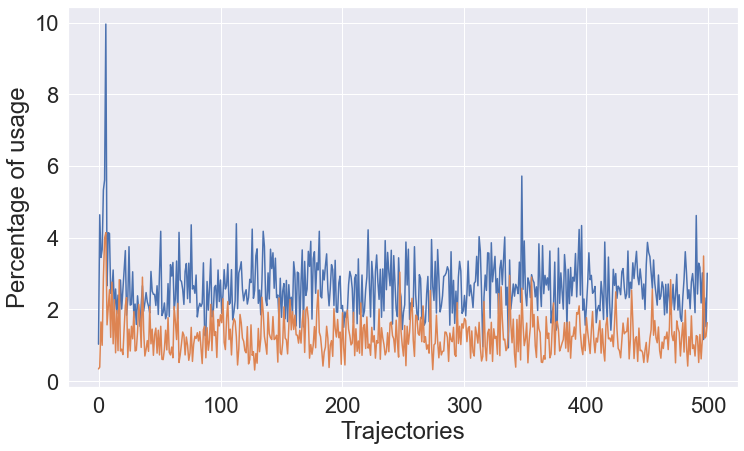

In [18]:
fig=plt.figure(figsize=(12, 7))
x='traj_n'
y='viol_constr'
temp_df_0 = ra0.loc[(df['type']!='S2')]
temp_df_1 = ra1.loc[(df['type']!='S2')]

#plt.legend(labels=['S1', 'S2'])
plt.xlabel("Trajectories")
plt.ylabel("Percentage of usage")

g=sns.lineplot(x=x, y=y, data=temp_df_0, ci=None, markers=True)
g=sns.lineplot(x=x, y=y, data=temp_df_1, ci=None, markers=True)
#g.legend_.set_title(None)
#plt.savefig(f'{y}.png', bbox_inches='tight')

2          0
3          0
14         1
15         1
26         2
        ... 
59967    497
59978    498
59979    498
59990    499
59991    499
Name: traj_n, Length: 10000, dtype: int64


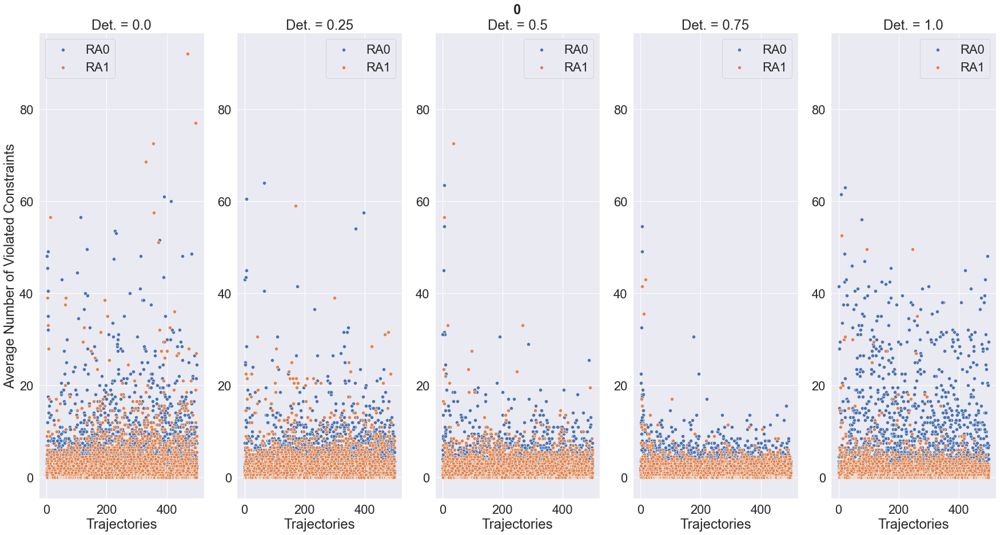

In [160]:
plot_type_new(x=x, y='Viol', df0=temp_df_0, df1=temp_df_1, hue='type', title='', filename='viol_constr')

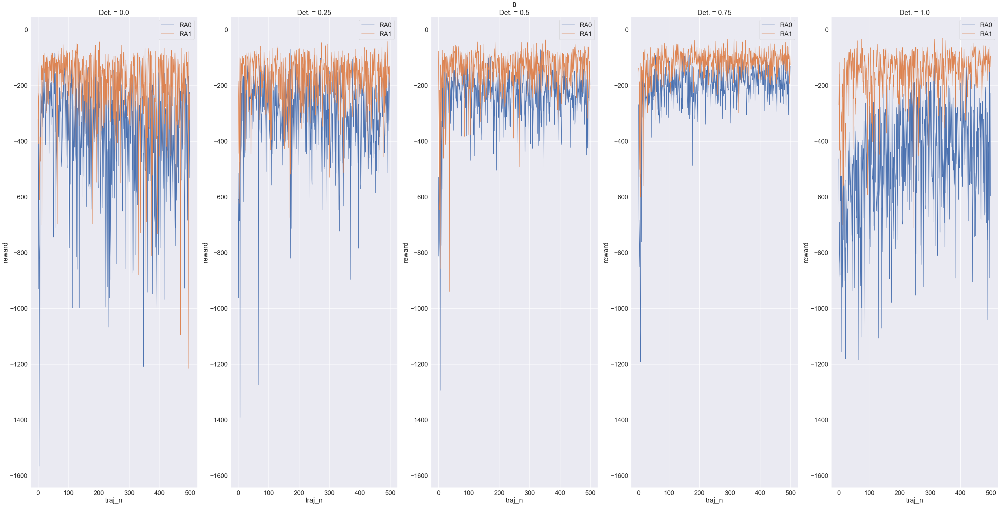

In [88]:


plot_type_new(x=x, y='reward', df0=temp_df_0, df1=temp_df_1, hue='type', title='', filename='reward')

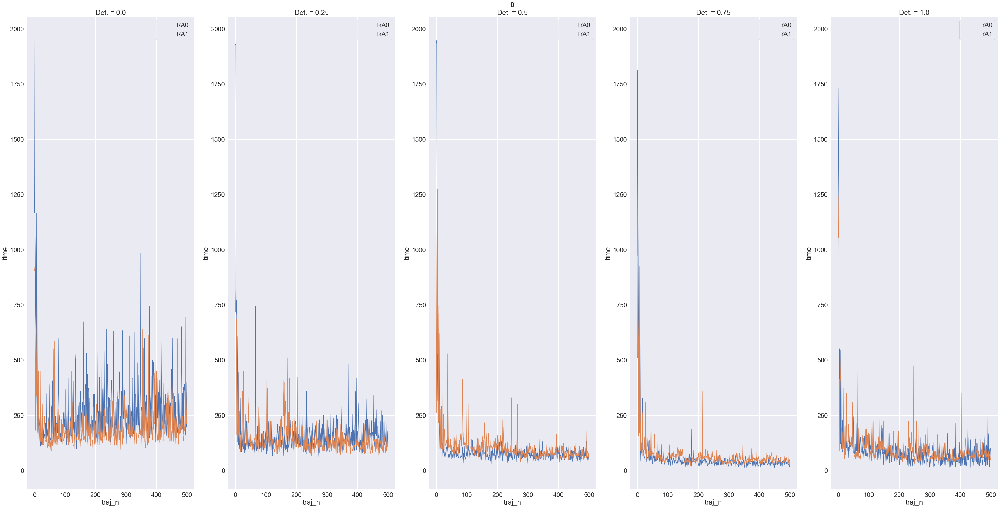

In [87]:
plot_type_new(x=x, y='time', df0=temp_df_0, df1=temp_df_1, hue='type', title='', filename='time')

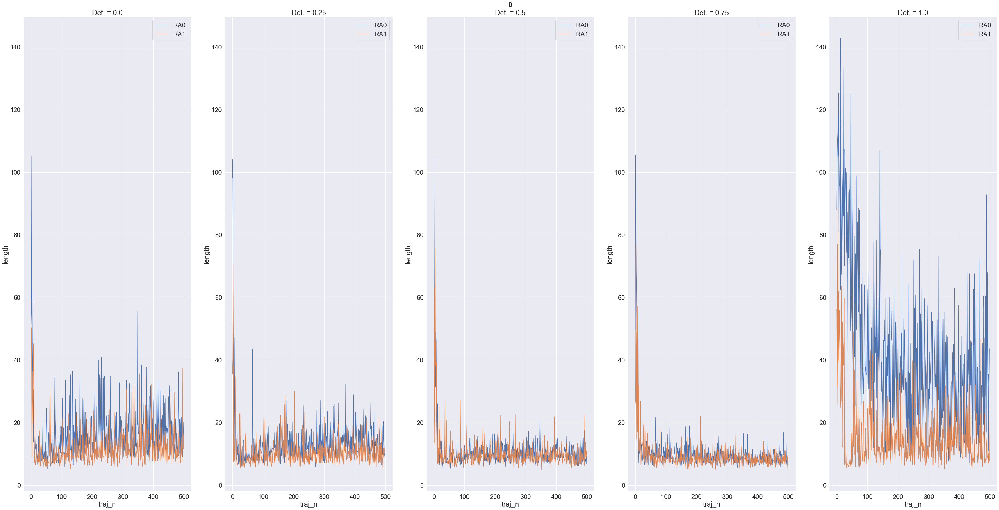

In [89]:
plot_type_new(x=x, y='length', df0=temp_df_0, df1=temp_df_1, hue='type', title='', filename='length')

In [108]:
temp_df1_delete = temp_df_1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.0')) ]

In [114]:
temp_df1_delete[['grid','traj_n','viol_constr','Viol']][100:120]

,grid,traj_n,viol_constr,Viol
602,0,50,0,0.0
603,0,50,0,0.0
614,0,51,0,3.0
615,0,51,6,3.0
626,0,52,0,4.0
627,0,52,8,4.0
638,0,53,0,0.5
639,0,53,1,0.5
650,0,54,0,0.5
651,0,54,1,0.5


'\nfig=plt.figure(figsize=(12, 7))\nsns.set(rc={\'figure.figsize\':(11.7,8.27)})\nsns.set_theme(style="whitegrid")\nsns.set(font_scale=2)\nsns.color_palette("viridis", as_cmap=True)\n\nlabel = \'viol_constr\'\nlabel = \'time\'\n#label = \'reward\'\n#label = \'length\'\n\ntemp_df = df.loc[(df[\'type\']==\'S2\')  | (df[\'type\']==\'SOFAI w/ S1 ra=1.0\')] #| (df[\'type\']==\'s1_nb\') \ntemp_df[\'type\'] = df[\'type\'].replace([\'SOFAI w/ S1 ra=1.0\'], \'SOFAI\')\ndf_means = temp_df.groupby(by=[\'type\',\'traj_n\']).agg(label=(label,\'mean\'))\nplt.legend(labels=[\'S2\', \'SOFAI\'])\n\n \ncolors = [\'#747FE3\', \'#32cd32\', \'#E37346\']\nsns.set_palette(sns.color_palette(colors))\n\nplt.xlabel("Trajectories")\nplt.ylabel("Time")\ng = sns.scatterplot(x=\'traj_n\', y=\'label\', data=df_means, hue=\'type\')\n#g.set_ylim([0, 1000])\ng.legend_.set_title(None)\nplt.savefig(f\'{label}.png\')\n'

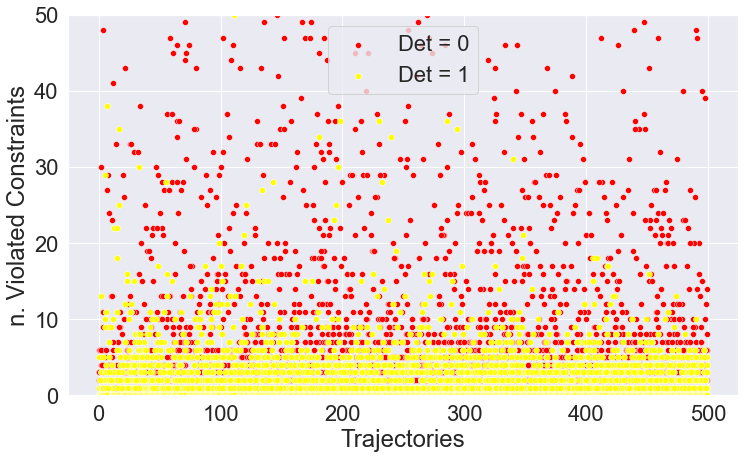

In [55]:
#plot_type_new(x=x, y='Viol', df0=temp_df_0, df1=temp_df_1, hue='type', title='', filename='viol_constr')
fig=plt.figure(figsize=(12, 7))
sns.set(rc={'figure.figsize':(11.7,8.27)})
sns.set_theme(style="whitegrid")
sns.set(font_scale=2)
#sns.color_palette("viridis", as_cmap=True)

temp_df0 = ra0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=1.0')) ]
temp_df1 = ra1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=1.0')) ]
#temp_df['type'] = df['type'].replace(['SOFAI w/ S1 ra=1.0'], 'SOFAI')

#if dropna : temp_df = temp_df.dropna()


plt.xlabel("Trajectories")
plt.ylabel("n. Violated Constraints")
#g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, markers=True, dashes=False, ci=None )
#g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, markers=True, dashes=False, ci=None )
label = 'viol_constr'

colors = ['#747FE3', '#32cd32', '#E37346']
sns.set_palette(sns.color_palette(colors))

g=sns.scatterplot(x='traj_n', y=label, data=temp_df0, color="red")
g=sns.scatterplot(x='traj_n', y=label, data=temp_df1, color="yellow")
plt.legend(labels=['Det = 0', 'Det = 1'])
#if max_label: g.set_ylim([min_label, max_label])
plt.legend(labels=['Det = 0', 'Det = 1'])
g.set_ylim([0, 50])

#plt.legend(loc='upper right')
#plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)


plt.savefig(f'{label}.png')
  
'''
fig=plt.figure(figsize=(12, 7))
sns.set(rc={'figure.figsize':(11.7,8.27)})
sns.set_theme(style="whitegrid")
sns.set(font_scale=2)
sns.color_palette("viridis", as_cmap=True)

label = 'viol_constr'
label = 'time'
#label = 'reward'
#label = 'length'

temp_df = df.loc[(df['type']=='S2')  | (df['type']=='SOFAI w/ S1 ra=1.0')] #| (df['type']=='s1_nb') 
temp_df['type'] = df['type'].replace(['SOFAI w/ S1 ra=1.0'], 'SOFAI')
df_means = temp_df.groupby(by=['type','traj_n']).agg(label=(label,'mean'))
plt.legend(labels=['S2', 'SOFAI'])

 
colors = ['#747FE3', '#32cd32', '#E37346']
sns.set_palette(sns.color_palette(colors))

plt.xlabel("Trajectories")
plt.ylabel("Time")
g = sns.scatterplot(x='traj_n', y='label', data=df_means, hue='type')
#g.set_ylim([0, 1000])
g.legend_.set_title(None)
plt.savefig(f'{label}.png')
'''

In [31]:
ra0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=1.0'))]

,Unnamed: 0,traj_n,length,reward,time,sub_type,time_agent,avg_time,reward_agent,avg_reward,...,Length,Reward,Viol,S1_Usage,t1,t2,t3,t4,t6,t7
10,0,0,6,-14.000000,139,s1,0,NaN,0.000000,NaN,...,6.0,-14.000000,0.0,0,200,0.8,0,0,1,0.5
11,0,0,6,-14.000000,139,s2,139,23.166667,-14.000000,-2.333333,...,6.0,-14.000000,0.0,0,200,0.8,0,0,1,0.5
22,1,1,7,-19.656854,43,s1,0,0.000000,-10.000000,-2.000000,...,7.0,-19.656854,0.0,0,200,0.8,0,0,1,0.5
23,1,1,7,-19.656854,43,s2,43,21.500000,-9.656854,-4.828427,...,7.0,-19.656854,0.0,0,200,0.8,0,0,1,0.5
34,2,2,201,-997.656854,4367,s1,0,0.000000,-100.000000,-50.000000,...,201.0,-997.656854,2.0,0,200,0.8,0,0,1,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59975,497,497,6,-122.284271,1,s2,0,NaN,0.000000,NaN,...,6.0,-122.284271,1.0,0,200,0.8,0,0,1,0.5
59986,498,498,201,-1101.656854,348,s1,348,1.731343,-1101.656854,-5.480880,...,201.0,-1101.656854,3.0,0,200,0.8,0,0,1,0.5
59987,498,498,201,-1101.656854,348,s2,0,NaN,0.000000,NaN,...,201.0,-1101.656854,3.0,0,200,0.8,0,0,1,0.5
59998,499,499,201,-1210.627417,322,s1,322,1.601990,-1210.627417,-6.023022,...,201.0,-1210.627417,4.0,0,200,0.8,0,0,1,0.5


In [16]:
#df[df['type']=='S2']

len(mca_agents[i_threshold2 * n_models + 10].modelSelf.trajectories)

500